<div style="font-size: 2em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
UE L2 Projet de Statistique CMI OSIA
</div>

</a>
<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Année 2026-2027
</div>
<div style="color: blue; font-size: 1.5em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Prévision de la disponibilité de vélos par régression linéaire
</div>


Dans ce calepin, il est présenté le principe de la régression linéaire et son application à la prévision du nombre de vélos disponibles dans des stations en libre service.

<div style="font-size: 1em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Principe de la régression linéaire
</div>

On suppose que l'on dispose de $n$ observations :

- de variables de réponses $Y_1,\ldots,Y_n$
- de $p$ variables explicatives $X_1^{(j)},\ldots,X_n^{(j)}$ pour $1 \leq j \leq p$

A partir de l'observation de nouvelles variables explicatives $\tilde{X}^{(j)}$ pour $1 \leq j \leq p$,  on souhaite prédire la réponse inconnue $\tilde{Y}$. 

**Exemple 1** : on suppose que $p=1$.  La variable de réponse est la taille d'un individu et la variable explicative est son poids. A partir de l'observations de $n$ couples (poids, taille) notés $(X_i,Y_i)_{1 \leq i \leq n}$ pour $n$ individus, on souhaite prévoir la taille d'un nouvel individu à partir de la donnée de son poids.

**Exemple 2** : on suppose que $p=2$. La variable de réponse est le nombre de vélos disponibles dans une station donnée à 17h00, et les variables explicatives sont  le nombre de vélos disponibles dans la même station  à 15h00 (variable $j=1$) et à 16h00  (variable $j=2$). On suppose que l'on observe $(Y_i,X_i^{(1)},X_i^{(2)})_{1 \leq i \leq n}$ pour $n$ jours pour une station donnée. A partir de l'observation du nombre de vélos à 15h00 et à 16h00 lors du jour $n+1$, on voudrait prévoir le nombre de vélos disponibles à 17h00 ce jour-là.

**Modèle linéaire**

Le modèle de régression linéaire consiste à modéliser la relation entre la variable de réponse et les $p$ variables explicatives comme étant approximativement linéaire c'est dire en supposant que
$$
Y_i \approx \hat{\theta}_0 + \sum_{j=1}^{p} \hat{\theta}_j X_i^{(j)}
$$
pour tout $1 \leq i \leq n$, où $\hat{\theta}_0,\hat{\theta}_1,\ldots,\hat{\theta}_p$ dont des coefficients inconnus qui sont calculés par minimisation de l'**erreur des moindres carrés** :
$$
\min_{(\theta_0,\theta_1,\ldots,\theta_p) \in \mathbb{R}^{p+1}} \sum_{i=1}^{n} \big(Y_i - \theta_0 - \sum_{j=1}^{p} \theta_j X_i^{(j)}\big)^2
$$
Ceci signifie que  $\hat{\theta}_0,\hat{\theta}_1,\ldots,\hat{\theta}_p$ sont calculés de sorte que
$$
\sum_{i=1}^{n} \big(Y_i - \hat{\theta}_0 - \sum_{j=1}^{p} \hat{\theta}_j X_i^{(j)}\big)^2 \leq \sum_{i=1}^{n} \big(Y_i - \theta_0 - \sum_{j=1}^{p} \theta_j X_i^{(j)}\big)^2,
$$
pour tout $(\theta_0,\theta_1,\ldots,\theta_p) \in \mathbb{R}^{p+1}$.

Dans le cas $p=1$, on retrouve le modèle de régression linéaire vu en L1 et en terminale.

**Prévision par régression linéaire**

Une fois effectué le calcul de $\hat{\theta}_0,\hat{\theta}_1,\ldots,\hat{\theta}_p$, la prévision de la variable réponse inconnue $\tilde{Y}$, à partir de nouvelles observations de variables explicatives $\tilde{X}^{(j)}$ pour $1 \leq j \leq p$, est donnée par 
$$
\hat{Y} =  \hat{\theta}_0 + \sum_{j=1}^{p} \hat{\theta}_j \tilde{X}_i^{(j)}
$$
Le calcul de $$\hat{\theta}_0,\hat{\theta}_1,\ldots,\hat{\theta}_p$$ peut se faire de façon mathématique mais ceci fait appel à des outils que vous verrez plus tard lors de votre cursus. Dans ce projet, vous allez apprendre à utiliser les outils de la librairie ``scikit-learn`` pour faire de la prévision par régression linéaire.  

**Régression linéaire simple avec $p=1$**

Le jeu de données ``load_diabetes`` contient des observations de patients et plusieurs variables mesurées. La variable réponse est une mesure quantitative de la progression de la maladie un an après les mesures initiales.

Pour commencer, on ne va utiliser qu'une seule variable explicative.

In [1]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()

print(diabetes.data.shape)
print(diabetes.feature_names)

(442, 10)
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


Il y a donc $n=442$ observations et $p=10$ variables explicatives.

Pour notre premier exemple, choisissons ``bmi`` (indice de masse corporelle) comme unique variable explicative.

In [2]:
# Choix de la variable explicative
X = diabetes.data[:, 2]

# Variable de réponse
Y = diabetes.target

print(len(X))
print(len(Y))

442
442


In [3]:
# Visualisation de quelques données
print(X[:5])
print(Y[:5])

[ 0.06169621 -0.05147406  0.04445121 -0.01159501 -0.03638469]
[151.  75. 141. 206. 135.]


Mathématiquement, on cherche donc un modèle de la forme
$$
Y_i \approx \hat{\theta}_0 + \hat{\theta}_1 X_i^{(1)}
$$

**Utilisation de** ``LinearRegression``

On importe maintenant le modèle de régression linéaire de ``scikit-learn``

In [4]:
from sklearn.linear_model import LinearRegression

# Création du modèle
modele = LinearRegression()

# Calcul des coefficients theta par ajustement (fit en Anglais) du modèle aux données
modele.fit(X.reshape(-1, 1), Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[949.44]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,152.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1.]


Pourquoi faire ``reshape(-1, 1)`` ?
Dans ``scikit-learn`` le modèle attend que les variables explicatives soient données sous la forme d'un tableau à deux dimensions $n \times p$

Ici, nous avons $n=442$ observations et $p=1$ variable explicative, donc $(442,1)$

In [5]:
print(X.shape)
print(X.reshape(-1, 1).shape)

(442,)
(442, 1)


In [6]:
# Pour eviter le reshape faire
X = diabetes.data[:, [2]]
Y = diabetes.target
print(X.shape)

modele = LinearRegression()
modele.fit(X, Y)

(442, 1)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[949.44]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,152.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[1.]


In [7]:
# Extraction des coefficients du modèle
print("θ0 =", modele.intercept_)
print("θ1 =", modele.coef_[0])

θ0 = 152.13348416289617
θ1 = 949.4352603840385


**Faire une prédiction avec** ``LinearRegression``

In [8]:
# Observation d'une nouvelle valeur de bmi
X_nouveau = [[0.05]]

# Prédiction
Y_predit = modele.predict(X_nouveau)

print(Y_predit)

[199.60524718]


**Que fait la fonction `.predict()` ?**

La méthode `.predict()` permet d'utiliser un modèle de régression qui a déjà été ajusté avec `.fit()` pour effectuer des prévisions.

Dans notre exemple, après l'appel
```python
modele.fit(X, Y)
```
le modèle a estimé les coefficients $\hat{\theta}_0$ et $\hat{\theta}_1$ du modèle

$$
Y \approx \hat{\theta}_0 + \hat{\theta}_1 X.
$$

Si nous observons ensuite une nouvelle valeur $\tilde{X}$ de la variable explicative, la méthode

```python
modele.predict([[tilde_X]])
```

calcule la valeur prédite

$$
\widehat{Y}
=
\hat{\theta}_0 + \hat{\theta}_1\tilde{X}.
$$

Ainsi, `.fit()` sert à apprendre les coefficients du modèle à partir des données disponibles, tandis que `.predict()` sert à utiliser le modèle appris pour obtenir une prévision à partir de nouvelles valeurs des variables explicatives.

Dans notre exemple :

```python
modele.fit(X, Y)
```

permet d'apprendre la relation entre l'IMC et la variable réponse, tandis que

```python
modele.predict(X_nouveau)
```

permet de prévoir la variable réponse pour une nouvelle observation dont on connaît l'IMC.


**Visualisation de la régression linéaire simple**


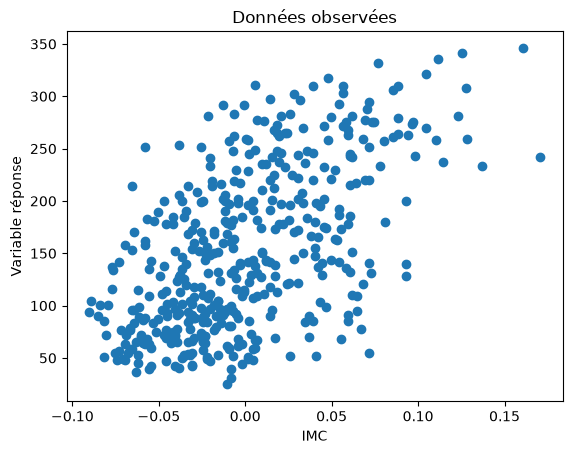

In [9]:
import matplotlib.pyplot as plt

plt.scatter(X, Y)

plt.xlabel("IMC")
plt.ylabel("Variable réponse")
plt.title("Données observées")

plt.show()

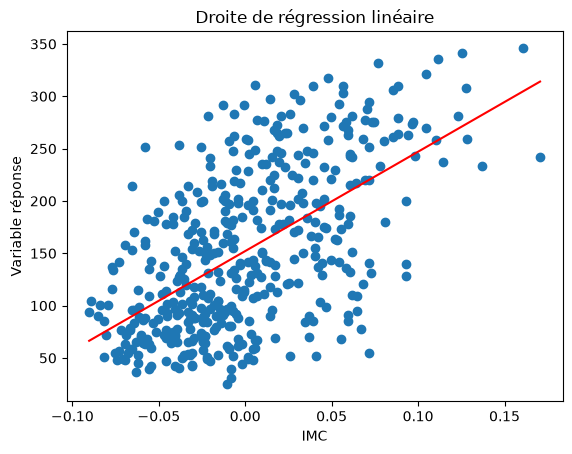

In [10]:
# Ajout de la droite de régression
import numpy as np

X_ligne = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
Y_ligne = modele.predict(X_ligne)

plt.scatter(X, Y)
plt.plot(X_ligne, Y_ligne, color='red')

plt.xlabel("IMC")
plt.ylabel("Variable réponse")
plt.title("Droite de régression linéaire")

plt.show()

**Généralisation au cas $p>1$**

On considère maintenant $p=3$ variables explicatives : ``bmi``, ``bp``et ``s5``

In [11]:
print(diabetes.feature_names)
X = diabetes.data[:, [2, 3, 8]]
Y = diabetes.target

print(X.shape)

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
(442, 3)


In [12]:
# Ajustement du modèle
modele = LinearRegression()

modele.fit(X, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[603.08,262.27,543.87]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,152.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[1.35,0.79,0.74]"


In [13]:
# Extraction des coefficients
print("θ0 =", modele.intercept_)
print("θ1, θ2, θ3 =", modele.coef_)

θ0 = 152.13348416289602
θ1, θ2, θ3 = [603.07835741 262.27200281 543.87120586]


In [14]:
# Prédiction
X_nouveau = [[0.05, 0.02, 0.04]]

Y_predit = modele.predict(X_nouveau)

print(Y_predit)

[209.28769032]


<div style="font-size: 1.5em; font-weight: bold; margin-top: 0.67em; margin-bottom: 0.67em;">
Application à la prévision du nombre de vélos
</div>

In [15]:
import pandas as pd

stations_toulouse = pd.read_parquet("stations_toulouse.parquet")

**Données d'entrainement**

``history_toulouse_train`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (nom de la station et date de mesure)
- des colonnes nommées ``bikes`` et ``stands``qui contiennent respectivement le nombre de vélos disponibles et le nombre de vélos manquants pour une station et une date (jour/heure) données

In [16]:
history_toulouse_train = pd.read_parquet("history_toulouse_train.parquet")
history_toulouse_train

bikes  stands
station                  commit_at                         
00001 - POIDS DE L'HUILE 2023-08-05 12:15:00     10       9
                         2023-08-05 12:30:00     10       9
                         2023-08-05 12:45:00     10       9
                         2023-08-05 13:00:00     11       8
                         2023-08-05 13:15:00     11       8
...                                             ...     ...
TEST BEE                 2026-02-12 15:00:00      0       3
                         2026-02-12 15:15:00      0       3
                         2026-02-12 15:30:00      0       3
                         2026-02-12 15:45:00      0       3
                         2026-02-12 16:00:00      0       3

[40012622 rows x 2 columns]

**Données de test**

``history_toulouse_test`` dans le code ci-dessous est un DataFrame Pandas, avec :
- des lignes identifiées par un MultiIndex (une station à la date de la dernière mesure faite dans les données d'entraînement)
- des colonnes nommées ``bikes_+15min``,...,``bikes_+120min`` qui doivent être complétées par des prévisions tous les 15 minutes pendant 2 heures

In [17]:
history_toulouse_test = pd.read_parquet("history_toulouse_test.parquet")
history_toulouse_test

,horizon,bikes_+15min,bikes_+30min,bikes_+45min,bikes_+60min,bikes_+75min,bikes_+90min,bikes_+105min,bikes_+120min
station,commit_at,,,,,,,,
00001 - POIDS DE L'HUILE,2026-07-31 21:45:00,6,6,6,6,6,6,6,6
00002 - LAFAYETTE,2026-07-31 23:45:00,10,10,10,10,10,10,10,10
00003 - ALSACE - LORRAINE - POMME,2025-11-10 11:45:00,4,4,4,4,4,4,4,4
00003 - ALSACE-LORRAINE - POMME,2026-07-31 21:45:00,6,6,6,6,6,6,6,6
00003 - POMME,2025-01-05 05:45:00,10,10,10,10,10,10,10,10
...,...,...,...,...,...,...,...,...,...
NARBONNE - CLOTASSES,2025-08-22 19:15:00,0,0,0,0,0,0,0,0
PASTEUR - LAVOISIER,2025-08-05 10:15:00,0,0,0,0,0,0,0,0
PLACE GEORGES BRASSENS,2025-08-05 11:00:00,0,0,0,0,0,0,0,0


**Construction des variables explicatives et de réponse**

Pour la station ``POIDS DE L'HUILE``, on va chercher à prédire le nombre de vélos à 22h00 (première prévision demandée après le 2026-07-31 21:45:00). Pour cela, pour chaque jour $i$, on propose de construire :

$$ X_i^{(1)} = \text{nombre de vélos à 20h00}, $$ $$ X_i^{(2)} = \text{nombre de vélos à 21h00}, $$

et

$$ Y_i = \text{nombre de vélos à 22h00}. $$

On considère le modèle de prédiction donc :

$$ \widehat Y_i = \hat\theta_0+ \hat\theta_1X_i^{(1)}+ \hat\theta_2X_i^{(2)}. $$

C'est exactement un problème de régression linéaire avec $p=2$.

In [18]:
import pandas as pd
from sklearn.linear_model import LinearRegression

station = "00001 - POIDS DE L'HUILE"

# Données de cette station uniquement
data_station = history_toulouse_train.xs(
    station,
    level="station"
).copy()

# En utilisant .xs, l'index de data_station est commit_at
data_station.head()

,bikes,stands
commit_at,,
2023-08-05 12:15:00,10,9
2023-08-05 12:30:00,10,9
2023-08-05 12:45:00,10,9
2023-08-05 13:00:00,11,8
2023-08-05 13:15:00,11,8


In [19]:
print(data_station.index.minute)

Index([15, 30, 45,  0, 15, 30, 45,  0, 15, 30,
       ...
       30, 45,  0, 15, 30, 45,  0, 15, 30, 45],
      dtype='int32', name='commit_at', length=104775)


In [20]:
print(data_station.index.hour)

Index([12, 12, 12, 13, 13, 13, 13, 14, 14, 14,
       ...
       19, 19, 20, 20, 20, 20, 21, 21, 21, 21],
      dtype='int32', name='commit_at', length=104775)


In [21]:
# On va sélectionner uniquement les observations de 20h, 21h et 22h.
data_station_small = data_station[
    data_station.index.minute.isin([0])
    & data_station.index.hour.isin([20, 21, 22])
].copy()

data_station_small

,bikes,stands
commit_at,,
2023-08-05 20:00:00,15,4
2023-08-05 21:00:00,15,4
2023-08-05 22:00:00,10,9
2023-08-06 20:00:00,19,0
2023-08-06 21:00:00,14,4
...,...,...
2026-07-30 20:00:00,14,4
2026-07-30 21:00:00,7,12
2026-07-30 22:00:00,7,12


In [22]:
data_station_small.index.normalize()

DatetimeIndex(['2023-08-05', '2023-08-05', '2023-08-05', '2023-08-06',
               '2023-08-06', '2023-08-06', '2023-08-07', '2023-08-07',
               '2023-08-07', '2023-08-08',
               ...
               '2026-07-28', '2026-07-28', '2026-07-29', '2026-07-29',
               '2026-07-29', '2026-07-30', '2026-07-30', '2026-07-30',
               '2026-07-31', '2026-07-31'],
              dtype='datetime64[us]', name='commit_at', length=3275, freq=None)

In [23]:
# Ajout du jour
data_station_small["day"] = data_station_small.index.normalize()
data_station_small["hour"] = data_station_small.index.hour
data_station_small

,bikes,stands,day,hour
commit_at,,,,
2023-08-05 20:00:00,15,4,2023-08-05,20
2023-08-05 21:00:00,15,4,2023-08-05,21
2023-08-05 22:00:00,10,9,2023-08-05,22
2023-08-06 20:00:00,19,0,2023-08-06,20
2023-08-06 21:00:00,14,4,2023-08-06,21
...,...,...,...,...
2026-07-30 20:00:00,14,4,2026-07-30,20
2026-07-30 21:00:00,7,12,2026-07-30,21
2026-07-30 22:00:00,7,12,2026-07-30,22


In [24]:
# Mise en colonndes des heures
data_station_hour = data_station_small.pivot(
    index="day",
    columns="hour",
    values="bikes"
)
data_station_hour

hour,20,21,22
day,,,
2023-08-05,15.0,15.0,10.0
2023-08-06,19.0,14.0,7.0
2023-08-07,8.0,7.0,6.0
2023-08-08,9.0,7.0,4.0
2023-08-09,15.0,15.0,15.0
...,...,...,...
2026-07-27,18.0,2.0,7.0
2026-07-28,8.0,8.0,4.0
2026-07-29,5.0,1.0,2.0


In [25]:
# On renomme les colonnes
data_station_hour = data_station_hour.rename(columns={
    20: "bikes_20h",
    21: "bikes_21h",
    22: "bikes_22h"
})
data_station_hour

hour,bikes_20h,bikes_21h,bikes_22h
day,,,
2023-08-05,15.0,15.0,10.0
2023-08-06,19.0,14.0,7.0
2023-08-07,8.0,7.0,6.0
2023-08-08,9.0,7.0,4.0
2023-08-09,15.0,15.0,15.0
...,...,...,...
2026-07-27,18.0,2.0,7.0
2026-07-28,8.0,8.0,4.0
2026-07-29,5.0,1.0,2.0


In [26]:
# Suppression de valeurs manques
data_station_hour = data_station_hour.dropna(
    subset=["bikes_20h", "bikes_21h", "bikes_22h"]
)
data_station_hour

hour,bikes_20h,bikes_21h,bikes_22h
day,,,
2023-08-05,15.0,15.0,10.0
2023-08-06,19.0,14.0,7.0
2023-08-07,8.0,7.0,6.0
2023-08-08,9.0,7.0,4.0
2023-08-09,15.0,15.0,15.0
...,...,...,...
2026-07-26,17.0,18.0,18.0
2026-07-27,18.0,2.0,7.0
2026-07-28,8.0,8.0,4.0


In [27]:
# Construction de X et Y
X = data_station_hour[["bikes_20h", "bikes_21h"]]
Y = data_station_hour["bikes_22h"]

print(X.shape)
print(Y.shape)

(1091, 2)
(1091,)


In [28]:
# Modèle de régression linéaire
model = LinearRegression()

model.fit(X, Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.09,0.79]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['bikes_20h','bikes_21h']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.1626
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [29]:
print("theta_0 =", model.intercept_)
print("theta_1 =", model.coef_[0])
print("theta_2 =", model.coef_[1])

theta_0 = 0.16256896757369788
theta_1 = 0.09046704698022909
theta_2 = 0.7850578353350229


In [30]:
data_station

,bikes,stands
commit_at,,
2023-08-05 12:15:00,10,9
2023-08-05 12:30:00,10,9
2023-08-05 12:45:00,10,9
2023-08-05 13:00:00,11,8
2023-08-05 13:15:00,11,8
...,...,...
2026-07-31 20:45:00,1,15
2026-07-31 21:00:00,1,15
2026-07-31 21:15:00,1,15


In [31]:
# Cacul de la prédiction
t0 = pd.Timestamp("2026-07-31 21:45:00")
print(data_station.loc[t0])
print(data_station.loc[t0.replace(hour=20)])
print(data_station.loc[t0.replace(hour=21)])

bikes     9
stands    7
Name: 2026-07-31 21:45:00, dtype: uint8
bikes      1
stands    15
Name: 2026-07-31 20:45:00, dtype: uint8
bikes     9
stands    7
Name: 2026-07-31 21:45:00, dtype: uint8


In [32]:
x_new = pd.DataFrame({
    "bikes_20h": [
        data_station.loc[t0.replace(hour=20), "bikes"]
    ],
    "bikes_21h": [
        data_station.loc[t0.replace(hour=21), "bikes"]
    ]
})

x_new

,bikes_20h,bikes_21h
0,1,9


In [33]:
prediction_22h = model.predict(x_new)[0]

print(np.round(prediction_22h))

7.0
